In [34]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

REQUIRED_FILES = [
    "hasil_cv_per_fold.csv",
    "hasil_cv_ringkasan.csv",
    "hasil_pemilihan_jumlah_fitur.csv",
    "fitur_terpilih_per_model.csv",
    "hasil_evaluasi_train_test_semua_model.csv",
    "prediksi_test_semua_model.csv",
]

OUTPUT_CANDIDATES = [
    Path(r"D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil")
]

folder_output = next(
    (
        folder
        for folder in OUTPUT_CANDIDATES
        if all((folder / filename).is_file() for filename in REQUIRED_FILES)
    ),
    None,
)

if folder_output is None:
    expected = "\n".join(f"- {folder}" for folder in OUTPUT_CANDIDATES)
    missing = "\n".join(f"- {filename}" for filename in REQUIRED_FILES)
    raise FileNotFoundError(
        "Hasil training lengkap tidak ditemukan. Pastikan skrip training "
        "sudah selesai dijalankan.\nFolder yang diperiksa:\n"
        f"{expected}\nFile yang dibutuhkan:\n{missing}"
    )

folder_gambar = folder_output / "Visualisasi"
folder_gambar.mkdir(parents=True, exist_ok=True)

print(f"Folder hasil training: {folder_output}")
print(f"Folder visualisasi: {folder_gambar}")

Folder hasil training: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil
Folder visualisasi: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Visualisasi


In [35]:
def read_result(filename: str) -> pd.DataFrame:
    return pd.read_csv(
        folder_output / filename,
        encoding="utf-8-sig",
    )


cv_folds = read_result("hasil_cv_per_fold.csv")
cv_summary = read_result("hasil_cv_ringkasan.csv")
feature_count_summary = read_result("hasil_pemilihan_jumlah_fitur.csv")
selected_features = read_result("fitur_terpilih_per_model.csv")
train_test_metrics = read_result("hasil_evaluasi_train_test_semua_model.csv")
test_predictions = read_result("prediksi_test_semua_model.csv")

required_columns = {
    "hasil_cv_per_fold.csv": {
        "Model", "n_features", "Fold", "MAE", "RMSE", "R2",
    },
    "hasil_cv_ringkasan.csv": {
        "Model", "n_features", "MAE_mean", "MAE_std",
        "RMSE_mean", "RMSE_std", "R2_mean", "R2_std",
    },
    "hasil_pemilihan_jumlah_fitur.csv": {
        "Model", "n_features", "MAE_mean", "MAE_std",
    },
    "fitur_terpilih_per_model.csv": {
        "Model", "feature", "f_score", "selected",
    },
    "hasil_evaluasi_train_test_semua_model.csv": {
        "Model", "Data", "MAE", "RMSE", "R2",
    },
    "prediksi_test_semua_model.csv": {"actual"},
}

frames = {
    "hasil_cv_per_fold.csv": cv_folds,
    "hasil_cv_ringkasan.csv": cv_summary,
    "hasil_pemilihan_jumlah_fitur.csv": feature_count_summary,
    "fitur_terpilih_per_model.csv": selected_features,
    "hasil_evaluasi_train_test_semua_model.csv": train_test_metrics,
    "prediksi_test_semua_model.csv": test_predictions,
}

for filename, required in required_columns.items():
    missing = required - set(frames[filename].columns)
    if missing:
        raise KeyError(
            f"Kolom {sorted(missing)} tidak ditemukan di {filename}."
        )

model_order = cv_summary.sort_values("MAE_mean")["Model"].tolist()

actual = pd.to_numeric(
    test_predictions["actual"],
    errors="coerce",
).to_numpy(dtype=float)

if len(actual) < 2 or not np.isfinite(actual).all():
    raise ValueError(
        "Kolom actual pada prediksi test harus memiliki minimal dua "
        "nilai numerik yang valid."
    )

print(f"Model yang divisualisasikan: {', '.join(model_order)}")

Model yang divisualisasikan: KNN, Random Forest, XGBoost, Gradient Boosting, DTS


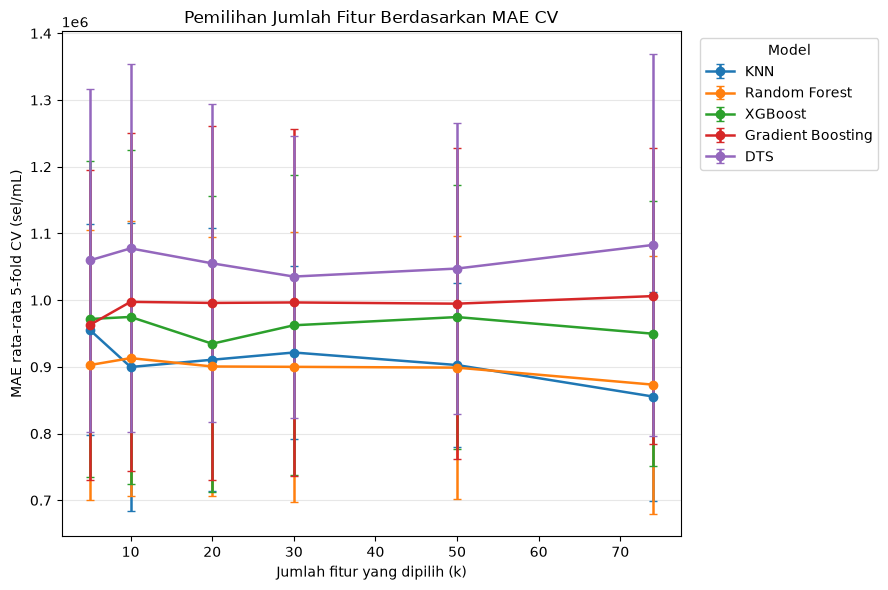

Disimpan: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Visualisasi\01_mae_vs_jumlah_fitur.png


In [36]:
fig, ax = plt.subplots(figsize=(9, 6))

for model_name in model_order:
    subset = feature_count_summary[
        feature_count_summary["Model"] == model_name
    ].sort_values("n_features")

    ax.errorbar(
        subset["n_features"],
        subset["MAE_mean"],
        yerr=subset["MAE_std"].fillna(0),
        marker="o",
        capsize=3,
        linewidth=1.8,
        label=model_name,
    )

ax.set_title("Pemilihan Jumlah Fitur Berdasarkan MAE CV")
ax.set_xlabel("Jumlah fitur yang dipilih (k)")
ax.set_ylabel("MAE rata-rata 5-fold CV (sel/mL)")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()

path = folder_gambar / "01_mae_vs_jumlah_fitur.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Disimpan: {path}")

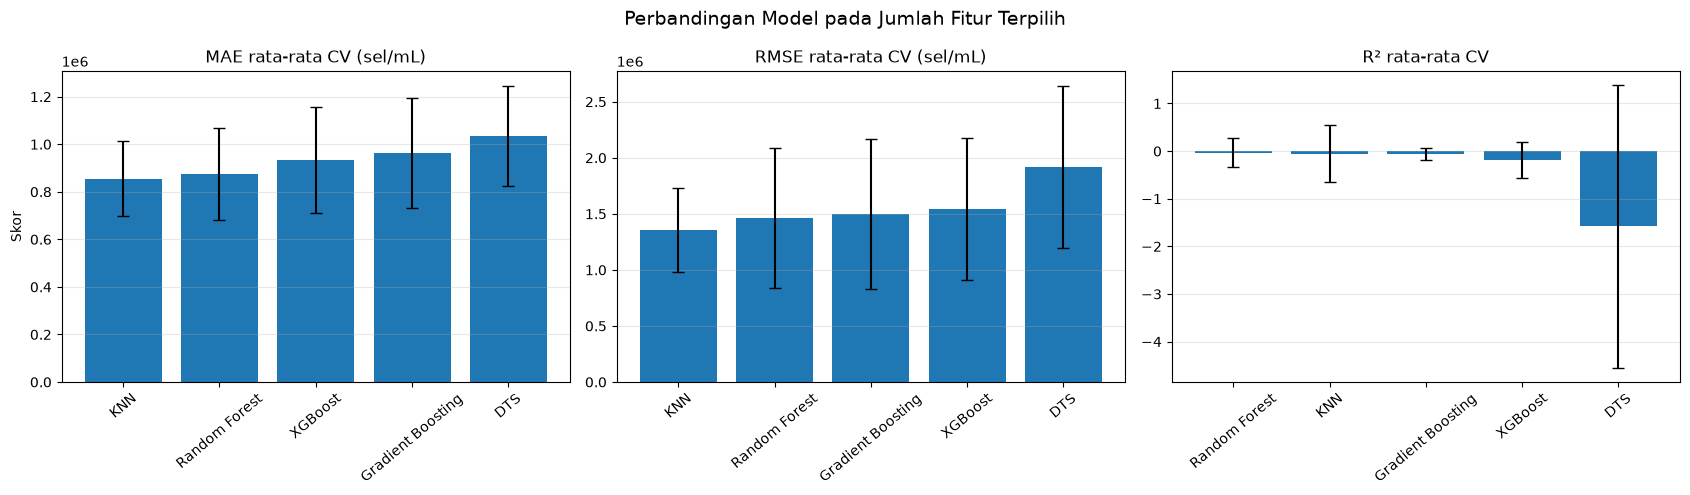

Disimpan: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Visualisasi\02_perbandingan_model_cv.png


In [37]:
cv_summary = (
    cv_summary
    .set_index("Model")
    .loc[model_order]
    .reset_index()
)

metric_specs = [
    ("MAE_mean", "MAE_std", "MAE rata-rata CV (sel/mL)", True),
    ("RMSE_mean", "RMSE_std", "RMSE rata-rata CV (sel/mL)", True),
    ("R2_mean", "R2_std", "R² rata-rata CV", False),
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (mean_col, std_col, title, lower_is_better) in zip(
    axes,
    metric_specs,
):
    plot_data = cv_summary.sort_values(
        mean_col,
        ascending=lower_is_better,
    )

    ax.bar(
        plot_data["Model"],
        plot_data[mean_col],
        yerr=plot_data[std_col].fillna(0),
        capsize=4,
    )
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=40)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Skor")
fig.suptitle(
    "Perbandingan Model pada Jumlah Fitur Terpilih",
    fontsize=14,
)
fig.tight_layout()

path = folder_gambar / "02_perbandingan_model_cv.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Disimpan: {path}")

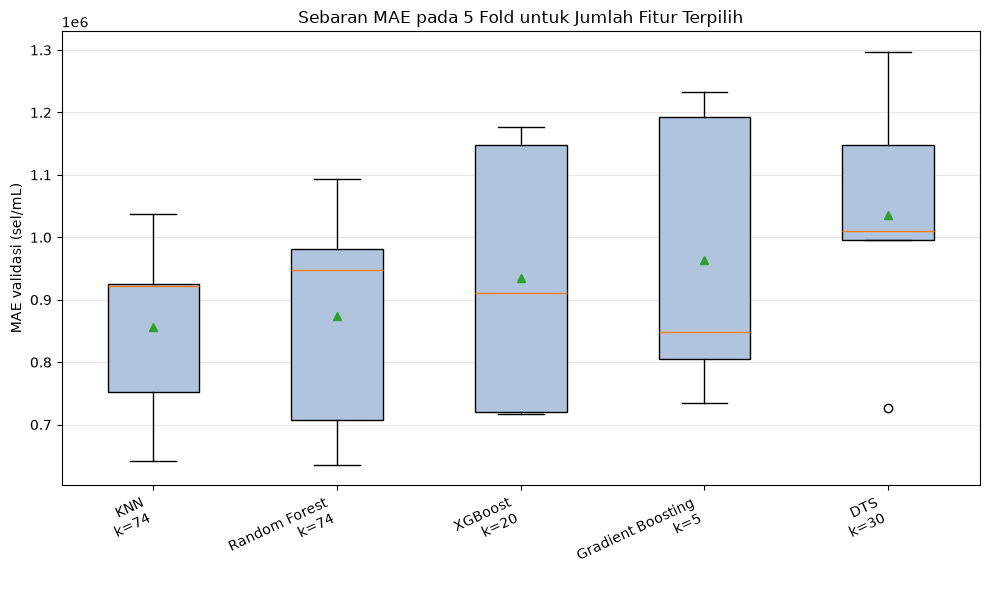

Disimpan: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Visualisasi\03_sebaran_mae_per_fold.png


In [38]:
selected_k = cv_summary.set_index("Model")["n_features"].to_dict()
fold_mae_values = []
fold_labels = []

for model_name in model_order:
    k = int(selected_k[model_name])

    values = cv_folds.loc[
        (cv_folds["Model"] == model_name)
        & (cv_folds["n_features"] == k),
        "MAE",
    ].dropna().to_numpy(dtype=float)

    if len(values) == 0:
        raise ValueError(
            f"MAE per-fold tidak ditemukan untuk {model_name} dengan k={k}."
        )

    fold_mae_values.append(values)
    fold_labels.append(f"{model_name}\nk={k}")

fig, ax = plt.subplots(figsize=(10, 6))

box = ax.boxplot(
    fold_mae_values,
    patch_artist=True,
    showmeans=True,
)

for patch in box["boxes"]:
    patch.set_facecolor("lightsteelblue")

ax.set_xticks(np.arange(1, len(fold_labels) + 1))
ax.set_xticklabels(fold_labels, rotation=25, ha="right")
ax.set_title("Sebaran MAE pada 5 Fold untuk Jumlah Fitur Terpilih")
ax.set_ylabel("MAE validasi (sel/mL)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()

path = folder_gambar / "03_sebaran_mae_per_fold.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Disimpan: {path}")

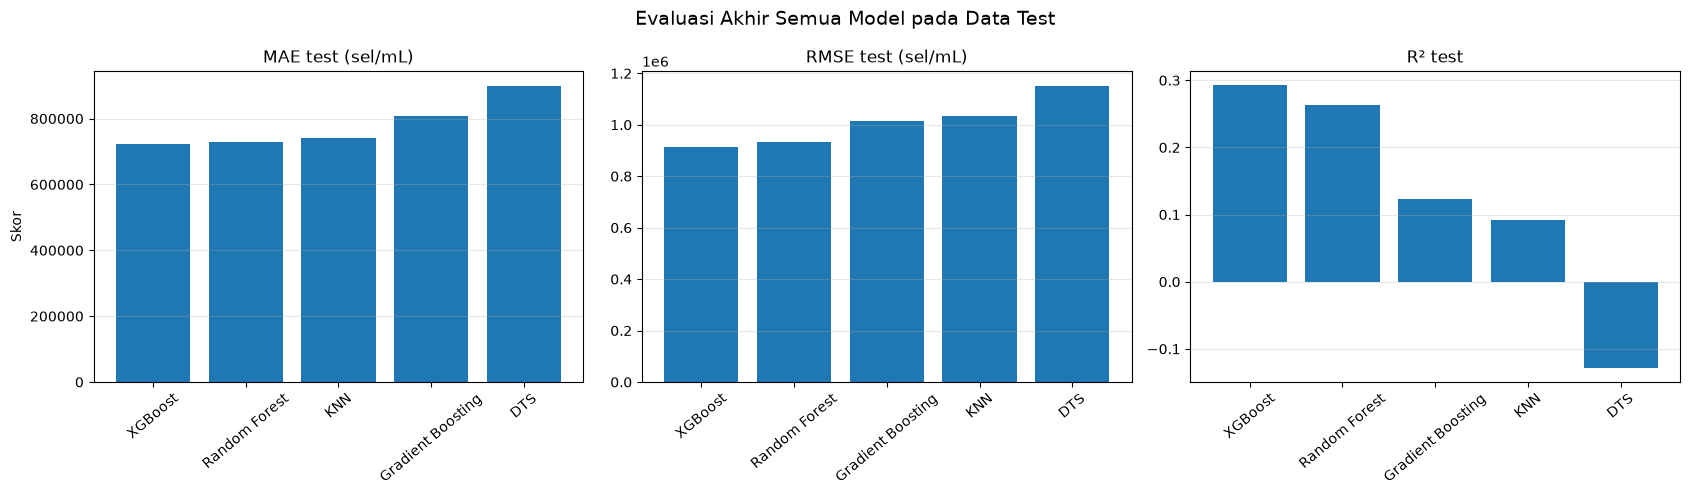

Disimpan: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Visualisasi\04_metrik_model_data_test.png


In [39]:
test_metrics = train_test_metrics[
    train_test_metrics["Data"] == "Test"
].copy()

if test_metrics.empty:
    raise ValueError("Tidak ada baris Data='Test' di CSV evaluasi.")

test_metrics = (
    test_metrics
    .set_index("Model")
    .reindex(model_order)
    .reset_index()
)

def add_metric_legend(ax, model_name: str) -> None:
    """Tampilkan MAE, RMSE, dan R2 model di bawah panel grafik."""
    row = test_metrics.loc[test_metrics["Model"] == model_name].iloc[0]
    handles = [
        Line2D(
            [], [], linestyle="none",
            label=f"MAE = {row['MAE']:,.0f}",
        ),
        Line2D(
            [], [], linestyle="none",
            label=f"RMSE = {row['RMSE']:,.0f}",
        ),
        Line2D(
            [], [], linestyle="none",
            label=f"R2 = {row['R2']:.3f}",
        ),
    ]
    ax.legend(
        handles=handles,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.20),
        ncol=3,
        fontsize=8,
        frameon=False,
        handlelength=0,
        handletextpad=0,
        columnspacing=1.0,
        borderaxespad=0,
    )

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

test_specs = [
    ("MAE", "MAE test (sel/mL)", True),
    ("RMSE", "RMSE test (sel/mL)", True),
    ("R2", "R² test", False),
]

for ax, (metric, title, lower_is_better) in zip(axes, test_specs):
    plot_data = test_metrics.sort_values(
        metric,
        ascending=lower_is_better,
    )

    ax.bar(plot_data["Model"], plot_data[metric])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=40)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Skor")
fig.suptitle("Evaluasi Akhir Semua Model pada Data Test", fontsize=14)
fig.tight_layout()

path = folder_gambar / "04_metrik_model_data_test.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Disimpan: {path}")

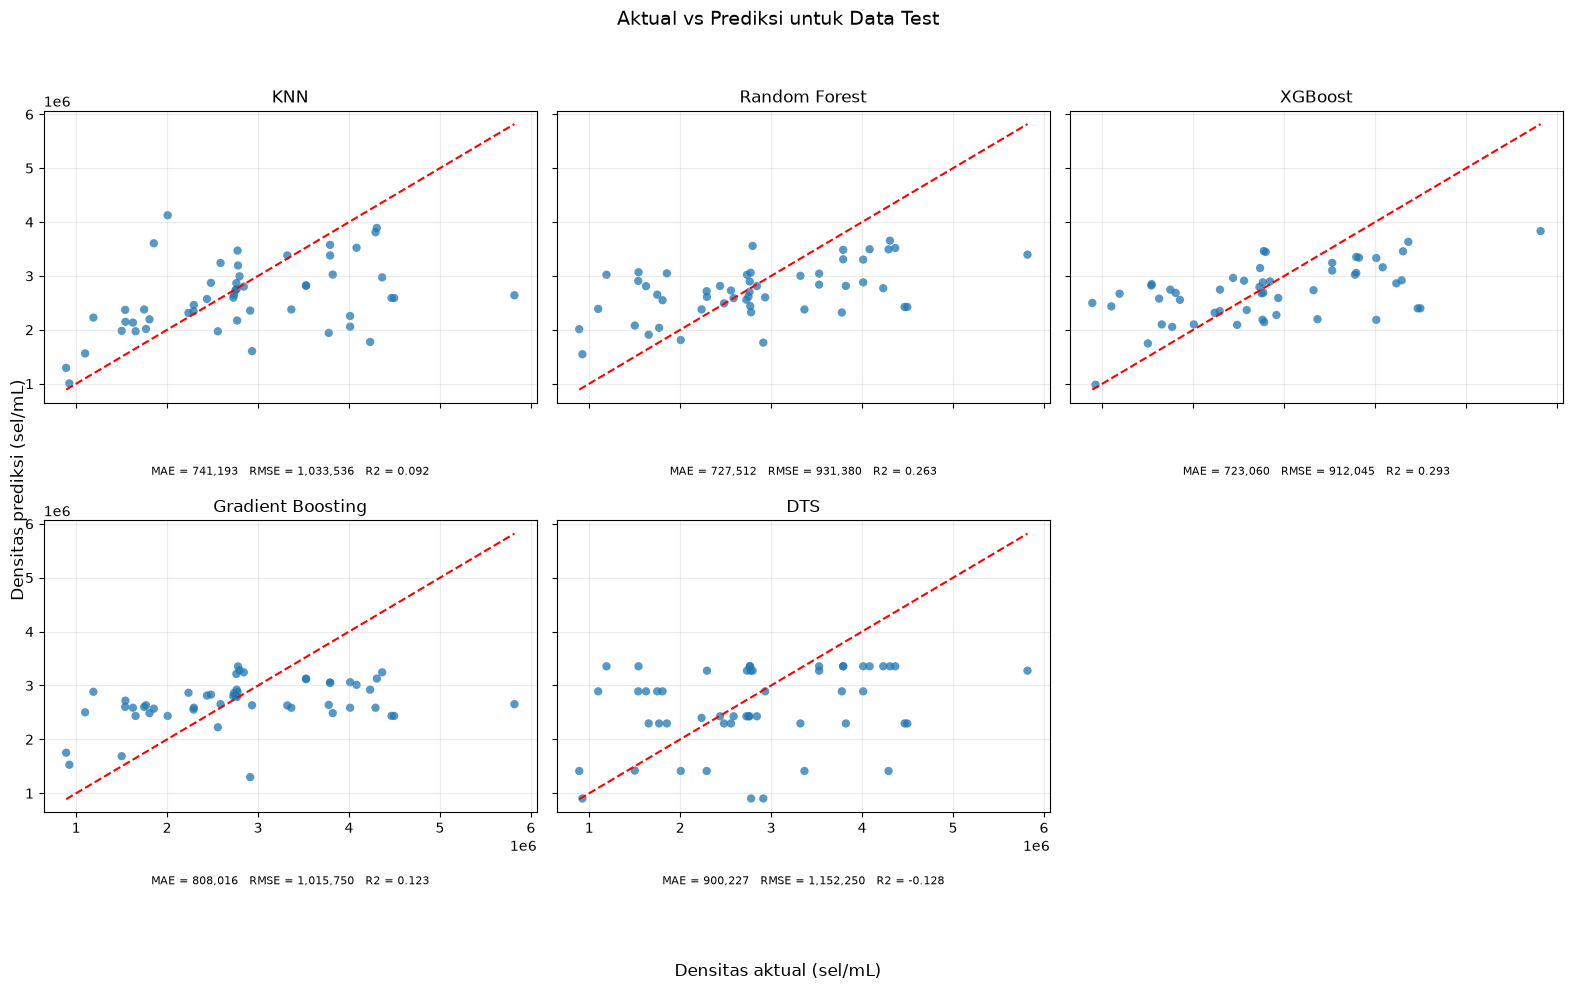

Disimpan: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Visualisasi\05_aktual_vs_prediksi_semua_model.png


In [40]:
prediction_columns = {
    column.removeprefix("predicted_"): column
    for column in test_predictions.columns
    if column.startswith("predicted_")
}

missing_models = set(model_order) - set(prediction_columns)

if missing_models:
    raise KeyError(
        f"Prediksi test tidak ditemukan untuk model: {sorted(missing_models)}"
    )

predicted_arrays = {}

for model_name in model_order:
    column = prediction_columns[model_name]

    predicted = pd.to_numeric(
        test_predictions[column],
        errors="coerce",
    ).to_numpy(dtype=float)

    if not np.isfinite(predicted).all():
        raise ValueError(
            f"Prediksi {model_name} mengandung nilai tidak valid."
        )

    predicted_arrays[model_name] = predicted

all_values = np.concatenate(
    [actual, *predicted_arrays.values()]
)

axis_min = float(np.min(all_values))
axis_max = float(np.max(all_values))

fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 10),
    sharex=True,
    sharey=True,
)
axes_flat = axes.ravel()

for ax, model_name in zip(axes_flat, model_order):
    predicted = predicted_arrays[model_name]

    ax.scatter(
        actual,
        predicted,
        alpha=0.75,
        edgecolors="none",
    )
    ax.plot(
        [axis_min, axis_max],
        [axis_min, axis_max],
        color="red",
        linestyle="--",
        linewidth=1.5,
    )

    ax.set_title(
        model_name
    )
    ax.grid(alpha=0.25)
    add_metric_legend(ax, model_name)

for ax in axes_flat[len(model_order):]:
    ax.axis("off")

fig.supxlabel("Densitas aktual (sel/mL)")
fig.supylabel("Densitas prediksi (sel/mL)")
fig.suptitle("Aktual vs Prediksi untuk Data Test", fontsize=14)
fig.tight_layout(rect=[0, 0.04, 1, 0.95], h_pad=0.4)

path = folder_gambar / "05_aktual_vs_prediksi_semua_model.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Disimpan: {path}")

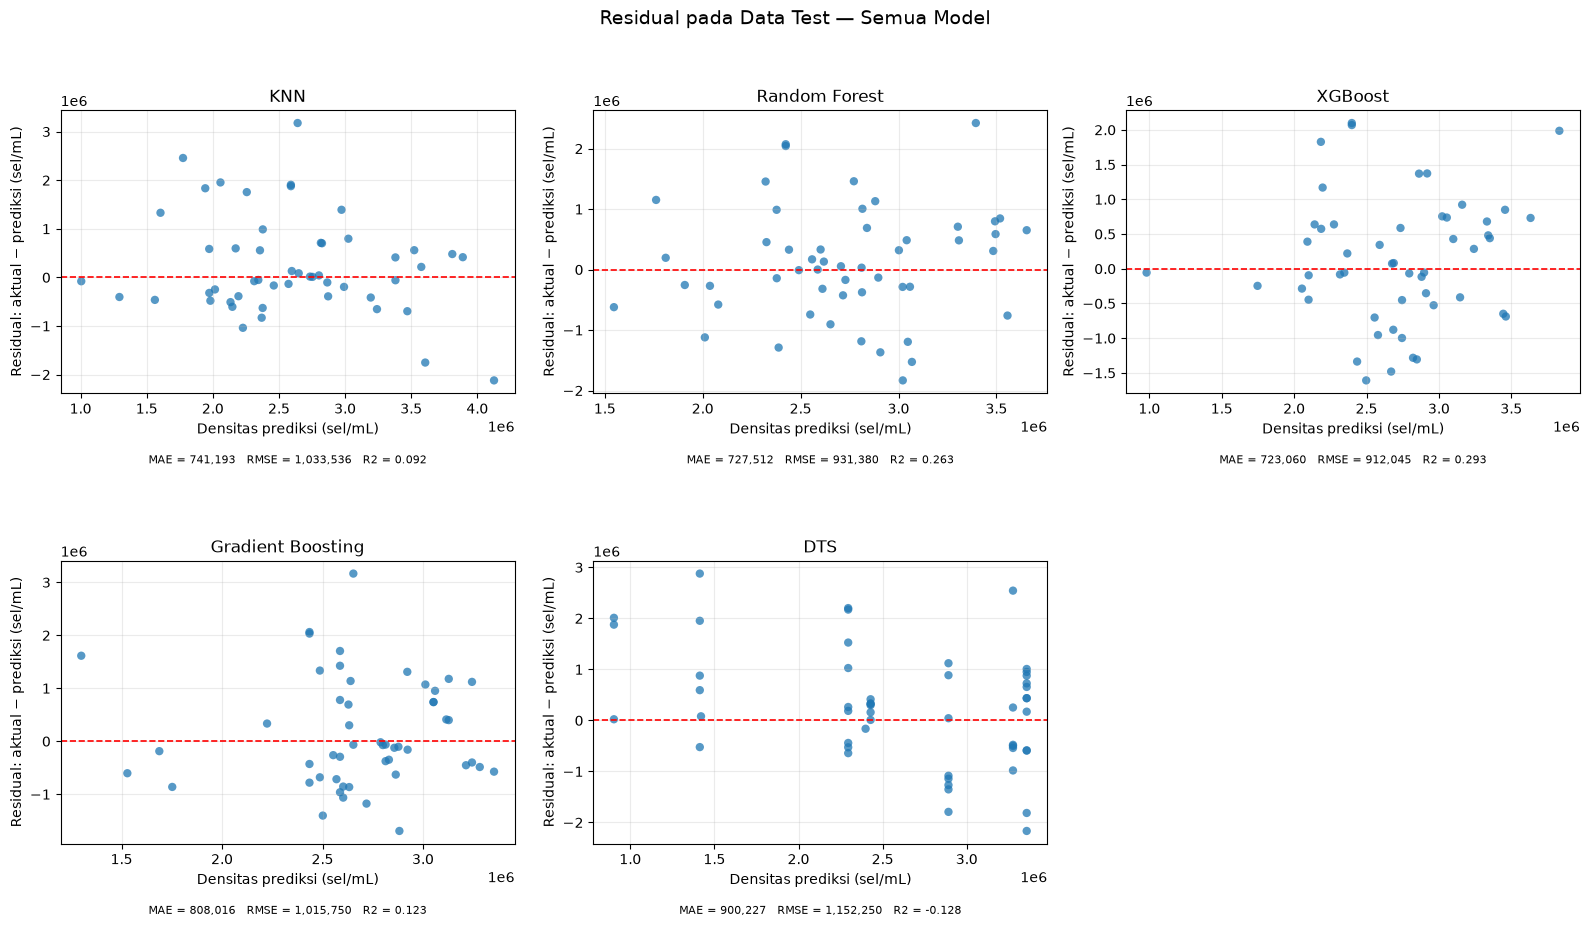

Disimpan: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Visualisasi\06_residual_semua_model.png


In [41]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes_flat = axes.ravel()

for ax, model_name in zip(axes_flat, model_order):
    predicted = predicted_arrays[model_name]
    residual = actual - predicted
    ax.scatter(predicted, residual, alpha=0.75, edgecolors="none")
    ax.axhline(0, color="red", linestyle="--", linewidth=1.2)
    ax.set_title(model_name)
    ax.set_xlabel("Densitas prediksi (sel/mL)")
    ax.set_ylabel("Residual: aktual − prediksi (sel/mL)")
    ax.grid(alpha=0.25)
    add_metric_legend(ax, model_name)

for ax in axes_flat[len(model_order):]:
    ax.axis("off")

fig.suptitle("Residual pada Data Test — Semua Model", fontsize=14)
fig.tight_layout(rect=(0, 0.04, 1, 0.95), h_pad=4.0)

path = folder_gambar / "06_residual_semua_model.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Disimpan: {path}")

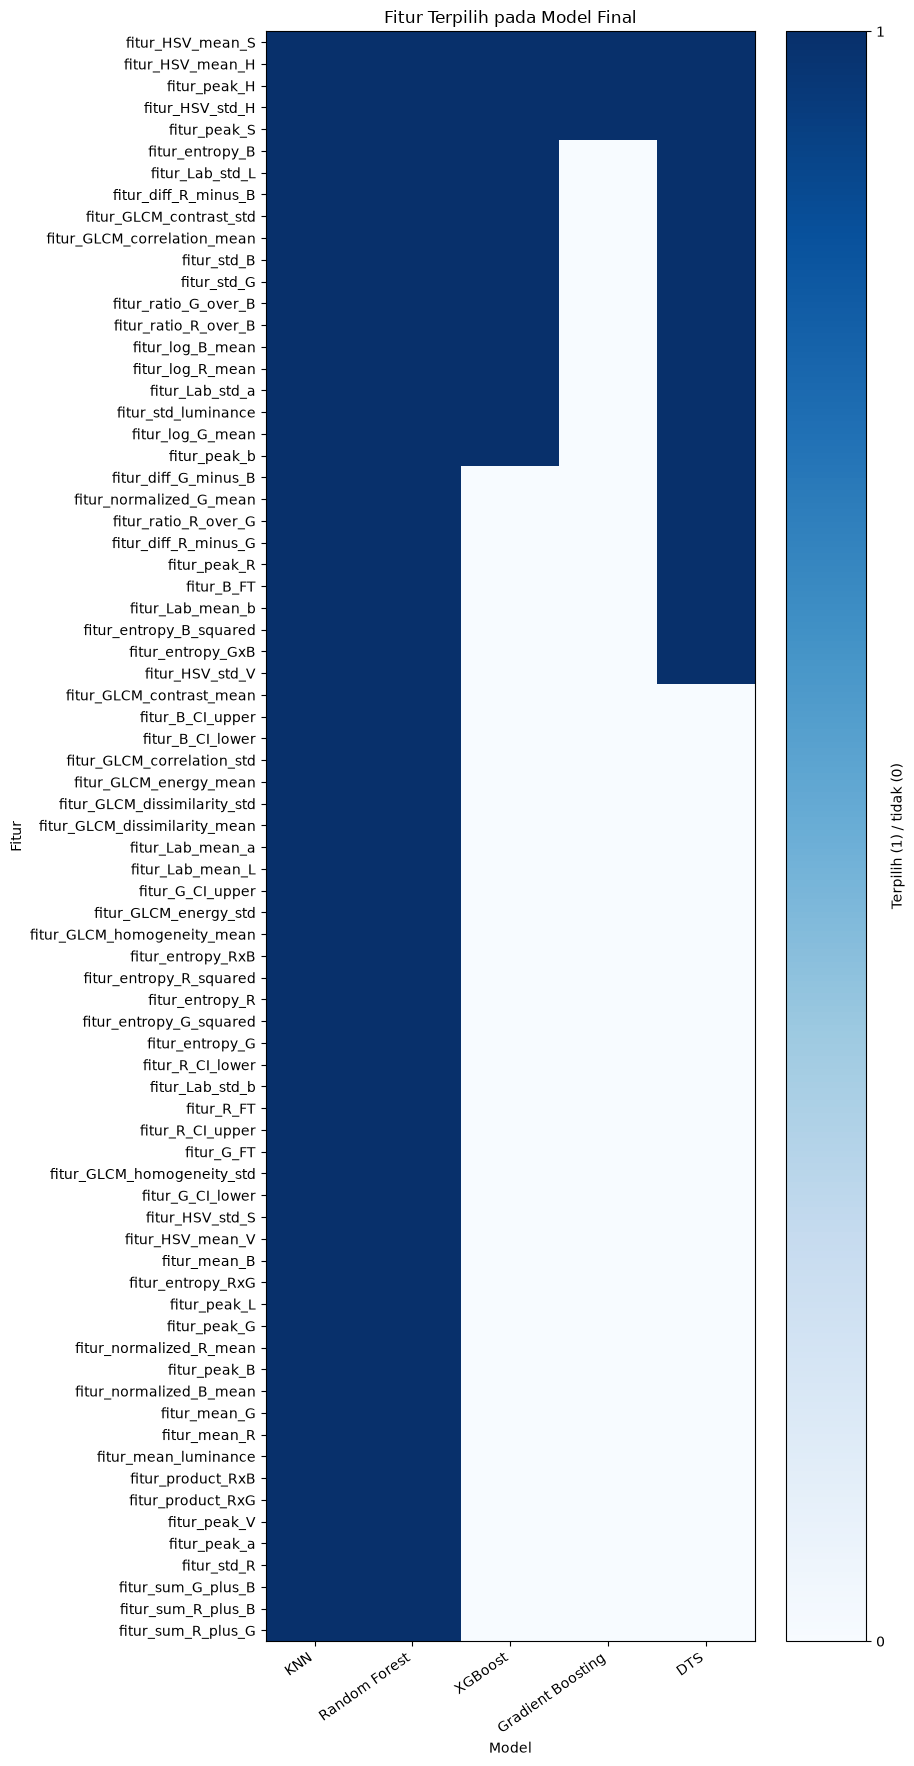

Disimpan: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Visualisasi\07_heatmap_fitur_terpilih.png


In [42]:
selected_features["selected"] = selected_features["selected"].map(
    lambda value: str(value).strip().lower()
    in {"true", "1", "yes"}
)

selection_matrix = selected_features.pivot(
    index="feature",
    columns="Model",
    values="selected",
).reindex(columns=model_order)

selection_matrix["jumlah_model_memilih"] = selection_matrix.sum(axis=1)

selection_matrix = selection_matrix.sort_values(
    "jumlah_model_memilih",
    ascending=False,
)

heatmap_data = selection_matrix.drop(
    columns="jumlah_model_memilih"
).astype(float)

fig_height = max(7, 0.24 * len(heatmap_data))

fig, ax = plt.subplots(
    figsize=(max(9, 1.5 * len(model_order)), fig_height)
)

image = ax.imshow(
    heatmap_data.to_numpy(),
    aspect="auto",
    interpolation="nearest",
    cmap="Blues",
    vmin=0,
    vmax=1,
)

ax.set_xticks(np.arange(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns, rotation=35, ha="right")
ax.set_yticks(np.arange(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)
ax.set_title("Fitur Terpilih pada Model Final")
ax.set_xlabel("Model")
ax.set_ylabel("Fitur")

fig.colorbar(
    image,
    ax=ax,
    ticks=[0, 1],
    label="Terpilih (1) / tidak (0)",
)
fig.tight_layout()

path = folder_gambar / "07_heatmap_fitur_terpilih.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Disimpan: {path}")

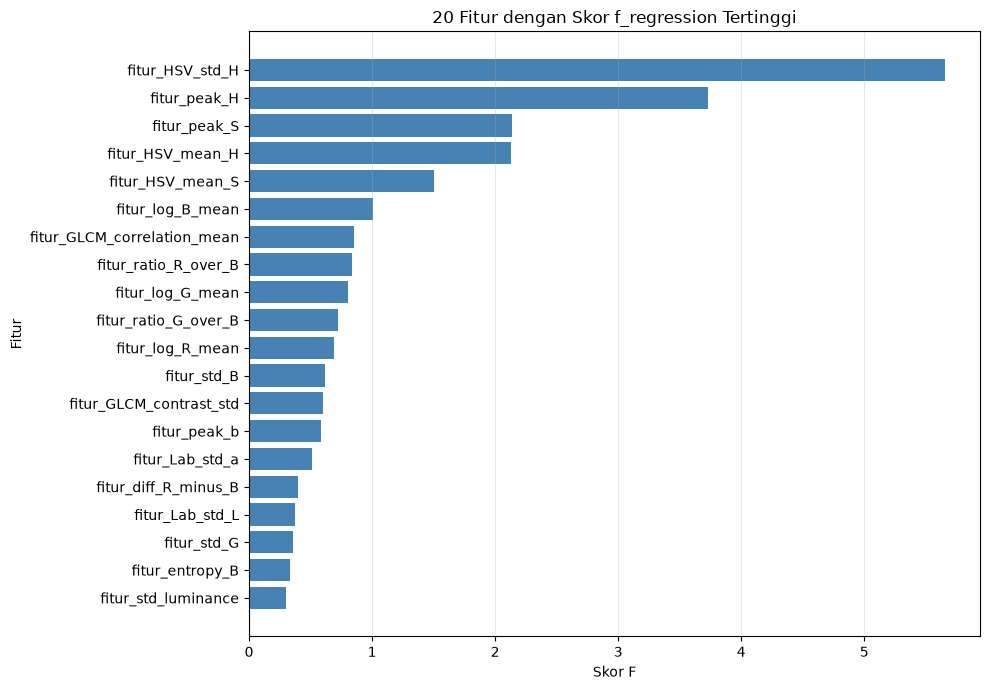

Disimpan: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Visualisasi\08_skor_f_20_teratas_semua_model.png
Selesai. Semua visualisasi tersedia di: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Visualisasi


In [ ]:
selected_features["f_score"] = pd.to_numeric(
    selected_features["f_score"], errors="coerce"
)

top_features = (
    selected_features[["feature", "f_score"]]
    .dropna(subset=["f_score"])
    .drop_duplicates(subset="feature")
)
top_features = top_features[
    np.isfinite(top_features["f_score"])
].nlargest(20, "f_score")

if top_features.empty:
    raise ValueError("Tidak ditemukan skor F numerik untuk divisualisasikan.")

top_features = top_features.sort_values("f_score")
fig_height = max(6, 0.35 * len(top_features))
fig, ax = plt.subplots(figsize=(10, fig_height))
ax.barh(
    top_features["feature"],
    top_features["f_score"],
    color="steelblue",
)
ax.set_title("20 Fitur dengan Skor f_regression Tertinggi")
ax.set_xlabel("Skor F")
ax.set_ylabel("Fitur")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()

path = folder_gambar / "08_skor_f_20_teratas_semua_model.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Disimpan: {path}")

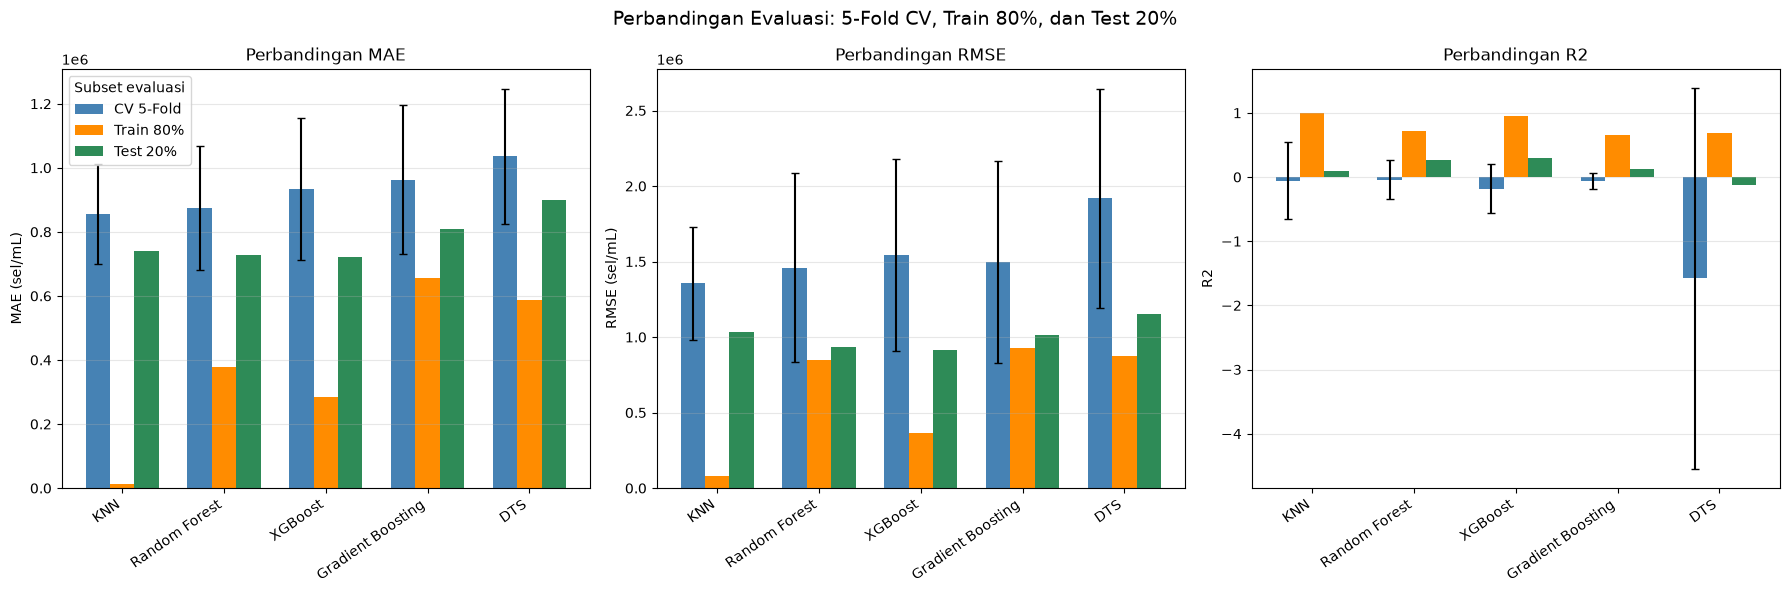

Disimpan: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Visualisasi\09_perbandingan_cv_train_test.png


In [ ]:
train_test_pivot = train_test_metrics.pivot(
    index="Model",
    columns="Data",
    values=["MAE", "RMSE", "R2"],
).reindex(model_order)

if not {"Train", "Test"}.issubset(
    set(train_test_metrics["Data"].astype(str).unique())
):
    raise ValueError(
        "CSV evaluasi harus memiliki nilai Train dan Test untuk semua model."
    )

comparison_specs = [
    ("MAE", "MAE (sel/mL)", "MAE_mean", "MAE_std"),
    ("RMSE", "RMSE (sel/mL)", "RMSE_mean", "RMSE_std"),
    ("R2", "R2", "R2_mean", "R2_std"),
]

x = np.arange(len(model_order))
bar_width = 0.24
dataset_specs = [
    ("CV 5-Fold", 0, "steelblue"),
    ("Train 80%", 1, "darkorange"),
    ("Test 20%", 2, "seagreen"),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (metric, ylabel, mean_col, std_col) in zip(
    axes,
    comparison_specs,
):
    cv_means = cv_summary.set_index("Model").loc[model_order, mean_col].to_numpy(dtype=float)
    cv_stds = cv_summary.set_index("Model").loc[model_order, std_col].fillna(0).to_numpy(dtype=float)
    train_values = train_test_pivot[(metric, "Train")].to_numpy(dtype=float)
    test_values = train_test_pivot[(metric, "Test")].to_numpy(dtype=float)

    values_by_dataset = {
        "CV 5-Fold": (cv_means, cv_stds),
        "Train 80%": (train_values, np.zeros_like(train_values)),
        "Test 20%": (test_values, np.zeros_like(test_values)),
    }

    for label, offset_index, color in dataset_specs:
        values, errors = values_by_dataset[label]
        ax.bar(
            x + (offset_index - 1) * bar_width,
            values,
            width=bar_width,
            yerr=errors if label == "CV 5-Fold" else None,
            capsize=3,
            color=color,
            label=label,
        )

    ax.set_title(f"Perbandingan {metric}")
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(model_order, rotation=35, ha="right")
    ax.grid(axis="y", alpha=0.3)

axes[0].legend(title="Subset evaluasi")
fig.suptitle(
    "Perbandingan Evaluasi: 5-Fold CV, Train 80%, dan Test 20%",
    fontsize=14,
)
fig.tight_layout()

path = folder_gambar / "09_perbandingan_cv_train_test.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Disimpan: {path}")

print(f"Selesai. Semua visualisasi tersedia di: {folder_gambar}")